# Robust Regression Engine — House Price Prediction


## Part A: Data Loading and Exploration

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, LeaveOneOut,
    TimeSeriesSplit, cross_val_score, GridSearchCV
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge, RidgeCV, LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score
)

RANDOM_STATE = 42

df = pd.read_csv("Advanced_Regression_HousePrice.csv")
print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (3800, 12)


,property_id,sale_date,area_sqft,bedrooms,bathrooms,location_score,property_age,distance_city_km,near_school,near_metro,crime_rate_index,house_price_inr
0,200001,01-01-2014,2181,6,4,8.1,21,3.8,0,0,4.84,35154898
1,200002,01-12-2019,2383,5,4,5.3,28,10.9,1,1,2.89,26710893
2,200003,01-10-2016,1047,3,3,5.9,7,27.5,0,1,4.04,11216242
3,200004,01-03-2013,1753,4,3,7.0,27,12.1,0,0,3.28,21984310
4,200005,01-07-2013,1728,4,4,10.0,32,1.4,0,1,3.84,25080429


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3800 entries, 0 to 3799
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   property_id       3800 non-null   int64  
 1   sale_date         3800 non-null   object 
 2   area_sqft         3800 non-null   int64  
 3   bedrooms          3800 non-null   int64  
 4   bathrooms         3800 non-null   int64  
 5   location_score    3800 non-null   float64
 6   property_age      3800 non-null   int64  
 7   distance_city_km  3800 non-null   float64
 8   near_school       3800 non-null   int64  
 9   near_metro        3800 non-null   int64  
 10  crime_rate_index  3800 non-null   float64
 11  house_price_inr   3800 non-null   int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 356.4+ KB


None

In [3]:
print("Missing values per column:")
display(df.isnull().sum().to_frame("missing_values"))
print("Duplicate rows:", df.duplicated().sum())
display(df.describe().T)

Missing values per column:


,missing_values
property_id,0
sale_date,0
area_sqft,0
bedrooms,0
bathrooms,0
location_score,0
property_age,0
distance_city_km,0
near_school,0
near_metro,0


Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
property_id,3800.0,2.019005e+05,1.097110e+03,200001.0,200950.75,201900.50,202850.25,203800.0
area_sqft,3800.0,1.716926e+03,5.829966e+02,500.0,1322.00,1700.50,2105.00,3776.0
bedrooms,3800.0,3.428158e+00,1.356682e+00,1.0,2.00,3.00,4.00,7.0
bathrooms,3800.0,2.916316e+00,1.133540e+00,1.0,2.00,3.00,4.00,6.0
location_score,3800.0,6.502237e+00,1.766945e+00,1.0,5.30,6.50,7.70,10.0
property_age,3800.0,2.253711e+01,1.232574e+01,1.0,14.00,20.00,29.00,80.0
distance_city_km,3800.0,1.308513e+01,6.537425e+00,1.0,8.50,13.00,17.50,38.7
near_school,3800.0,5.484211e-01,4.977154e-01,0.0,0.00,1.00,1.00,1.0
near_metro,3800.0,4.728947e-01,4.993305e-01,0.0,0.00,0.00,1.00,1.0
crime_rate_index,3800.0,4.242911e+00,2.045371e+00,0.5,2.81,4.22,5.65,12.0


## Part B: Feature Engineering and Train/Test Split

The sale date is parsed using day-first format because the dataset contains dates such as `01-12-2019`. We extract day, month, and year. `property_id` is excluded because it is an identifier, not a meaningful property characteristic; including it may let the model exploit row/order patterns that do not generalize.

In [4]:
data = df.copy()
data["sale_date"] = pd.to_datetime(data["sale_date"], dayfirst=True, errors="coerce")
if data["sale_date"].isna().any():
    raise ValueError("Some sale_date values could not be parsed. Check the source date format.")

data["sale_day"] = data["sale_date"].dt.day
data["sale_month"] = data["sale_date"].dt.month
data["sale_year"] = data["sale_date"].dt.year
data = data.drop(columns=["sale_date", "property_id"])

TARGET = "house_price_inr"
X = data.drop(columns=[TARGET])
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Target range:", int(y.min()), "to", int(y.max()))

X_train: (3040, 12) | X_test: (760, 12)
Target range: 1506126 to 59303146


## Part C: Regularized Linear Models

Ridge uses L2 regularization; Lasso uses L1 regularization. `RidgeCV` and `LassoCV` select alpha using 5-fold cross-validation. Scaling is fitted on training data only, using a pipeline to avoid data leakage.

In [6]:
alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge_model = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=alphas, cv=5)
)
lasso_model = make_pipeline(
    StandardScaler(),
    LassoCV(alphas=alphas, cv=5, max_iter=20000, random_state=RANDOM_STATE)
)

ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

ridge_est = ridge_model.named_steps["ridgecv"]
lasso_est = lasso_model.named_steps["lassocv"]
print("Ridge best alpha:", ridge_est.alpha_)
print("Lasso best alpha:", lasso_est.alpha_)

Ridge best alpha: 1.0
Lasso best alpha: 1000.0


In [7]:
def regression_metrics(y_true, y_pred):
    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

linear_rows = []
for name, model in [("Ridge", ridge_model), ("Lasso", lasso_model)]:
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    linear_rows.append({
        "Model": name,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test MAE": mean_absolute_error(y_test, test_pred)
    })
linear_comparison = pd.DataFrame(linear_rows)
display(linear_comparison.round(4))

,Model,Train R2,Test R2,Train RMSE,Test RMSE,Test MAE
0,Ridge,0.9174,0.9199,2.482399e+06,2.539952e+06,1.945385e+06
1,Lasso,0.9174,0.9199,2.482396e+06,2.539903e+06,1.945576e+06


,Feature,Ridge coefficient,Lasso coefficient,Lasso is zero
0,area_sqft,6948656.092,6955326.524,False
3,location_score,3678704.843,3680270.695,False
4,property_age,-649942.470,-649214.235,False
11,sale_year,300962.150,300159.844,False
1,bedrooms,295295.762,289115.241,False
2,bathrooms,273072.987,272638.906,False
8,crime_rate_index,-140692.147,-139671.028,False
7,near_metro,52546.423,51648.603,False
5,distance_city_km,-28521.048,-26496.649,False
10,sale_month,17420.954,16369.591,False


Ridge zero coefficients: 1
Lasso zero coefficients: 1


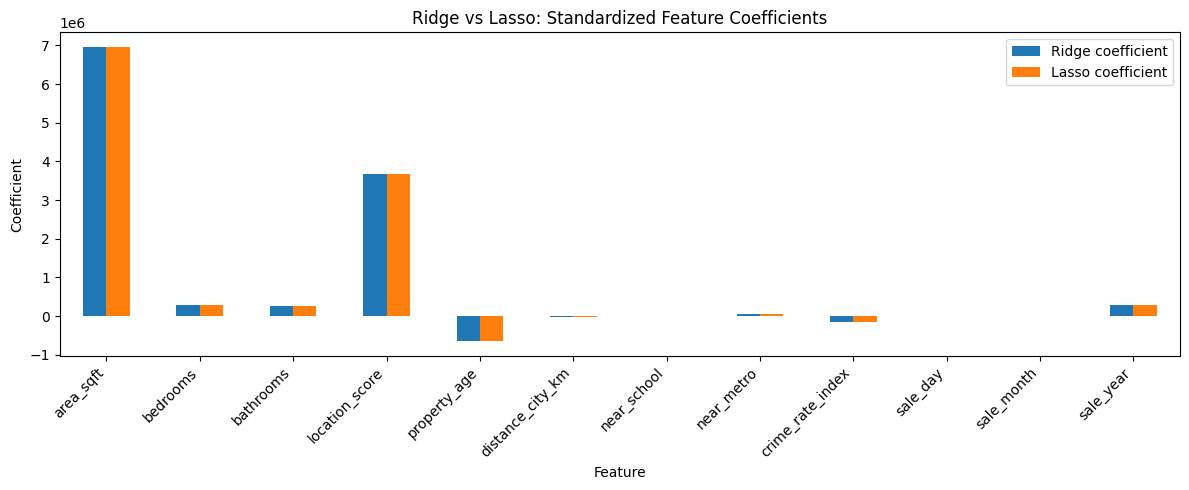

In [8]:
# Coefficients are in standardized-feature units because StandardScaler is used.
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Ridge coefficient": ridge_est.coef_,
    "Lasso coefficient": lasso_est.coef_
})
coef_df["Lasso is zero"] = np.isclose(coef_df["Lasso coefficient"], 0)
display(coef_df.sort_values("Ridge coefficient", key=lambda s: s.abs(), ascending=False).round(3))
print("Ridge zero coefficients:", int(np.isclose(ridge_est.coef_, 0).sum()))
print("Lasso zero coefficients:", int(np.isclose(lasso_est.coef_, 0).sum()))

coef_plot = coef_df.set_index("Feature")[["Ridge coefficient", "Lasso coefficient"]]
coef_plot.plot(kind="bar", figsize=(12, 5))
plt.title("Ridge vs Lasso: Standardized Feature Coefficients")
plt.ylabel("Coefficient")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**How to interpret Part C:** Ridge usually shrinks coefficients toward zero without removing features. Lasso can set some coefficients exactly to zero. Compare both training and test errors, not just the selected alpha.

## Part D: Cross-Validation Strategies

The same Ridge pipeline is evaluated with four strategies. Stratified K-Fold is adapted for regression by binning the target price into quantiles. Time Series Split sorts records by sale date and trains on earlier observations to validate on later ones. LOOCV can be slower because it fits one model per observation.

In [9]:
cv_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
cv_rows = []

# 1. Standard K-Fold
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(cv_model, X_train, y_train, cv=kf,
                         scoring="neg_mean_squared_error", n_jobs=-1)
cv_rows.append({"CV Strategy": "K-Fold (5)", "Mean CV RMSE": np.sqrt(-scores.mean()),
                "Std. Fold RMSE": np.sqrt(-scores).std()})

# 2. Stratified K-Fold using target quantile bins
y_bins = pd.qcut(y_train, q=5, labels=False, duplicates="drop")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(cv_model, X_train, y_train,
                         cv=skf.split(X_train, y_bins),
                         scoring="neg_mean_squared_error", n_jobs=-1)
cv_rows.append({"CV Strategy": "Stratified K-Fold (5 bins)", "Mean CV RMSE": np.sqrt(-scores.mean()),
                "Std. Fold RMSE": np.sqrt(-scores).std()})

# 3. Leave-One-Out CV (computationally more expensive)
loo = LeaveOneOut()
scores = cross_val_score(cv_model, X_train, y_train, cv=loo,
                         scoring="neg_mean_squared_error", n_jobs=-1)
cv_rows.append({"CV Strategy": "Leave-One-Out", "Mean CV RMSE": np.sqrt(-scores.mean()),
                "Std. Fold RMSE": np.sqrt(-scores).std()})

# 4. Time Series Split: sort by sale date, then use earlier records to predict later records
time_data = df.copy()
time_data["sale_date"] = pd.to_datetime(time_data["sale_date"], dayfirst=True, errors="coerce")
time_data = time_data.sort_values("sale_date")
time_data["sale_day"] = time_data["sale_date"].dt.day
time_data["sale_month"] = time_data["sale_date"].dt.month
time_data["sale_year"] = time_data["sale_date"].dt.year
time_data = time_data.drop(columns=["sale_date", "property_id"])
X_time = time_data.drop(columns=[TARGET])
y_time = time_data[TARGET]

tscv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(cv_model, X_time, y_time, cv=tscv,
                         scoring="neg_mean_squared_error", n_jobs=-1)
cv_rows.append({"CV Strategy": "Time Series Split (5)", "Mean CV RMSE": np.sqrt(-scores.mean()),
                "Std. Fold RMSE": np.sqrt(-scores).std()})

cv_comparison = pd.DataFrame(cv_rows).sort_values("Mean CV RMSE")
display(cv_comparison.round(2))

,CV Strategy,Mean CV RMSE,Std. Fold RMSE
1,Stratified K-Fold (5 bins),2492172.51,78045.83
2,Leave-One-Out,2493070.54,1608520.93
0,K-Fold (5),2496838.13,88893.46
3,Time Series Split (5),2505905.88,74564.56


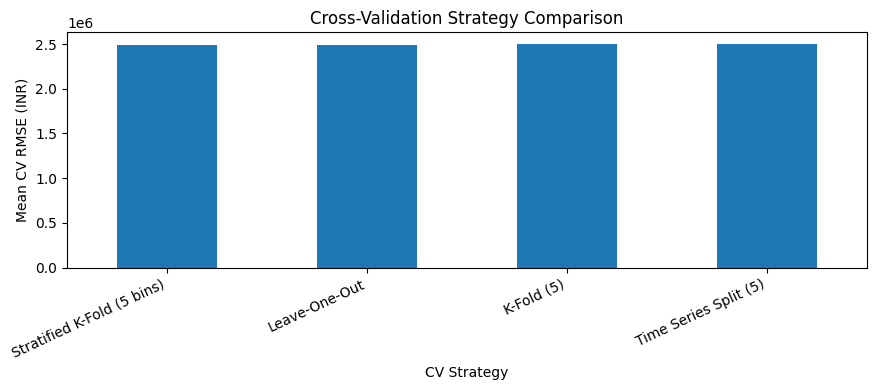

In [10]:
cv_comparison.plot(x="CV Strategy", y="Mean CV RMSE", kind="bar", legend=False, figsize=(9, 4))
plt.ylabel("Mean CV RMSE (INR)")
plt.title("Cross-Validation Strategy Comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

**How to interpret Part D:** Lower mean CV RMSE is better. The standard deviation indicates how much scores vary across folds. Random K-Fold assumes observations can be randomly mixed; Time Series Split is more suitable when the real use case is predicting future prices from past sales.

## Part E: Tree-Based Regression Models

A Decision Tree is compared with a depth-controlled tree and a Random Forest ensemble. Tree models do not require feature scaling.

In [11]:
tree_models = {
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Tuned Decision Tree": DecisionTreeRegressor(
        max_depth=10, min_samples_leaf=5, min_samples_split=10,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=10, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

tree_rows = []
fitted_tree_models = {}
for name, model in tree_models.items():
    model.fit(X_train, y_train)
    fitted_tree_models[name] = model
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    tree_rows.append({
        "Model": name,
        "Train R2": r2_score(y_train, pred_train),
        "Test R2": r2_score(y_test, pred_test),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, pred_train)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
        "Test MAE": mean_absolute_error(y_test, pred_test)
    })
tree_comparison = pd.DataFrame(tree_rows)
display(tree_comparison.round(4))

,Model,Train R2,Test R2,Train RMSE,Test RMSE,Test MAE
0,Decision Tree,1.0000,0.8665,0.000000e+00,3.278407e+06,2385453.800
1,Tuned Decision Tree,0.9621,0.8917,1.680808e+06,2.953891e+06,2155390.836
2,Random Forest,0.9767,0.9290,1.319181e+06,2.390665e+06,1745461.474


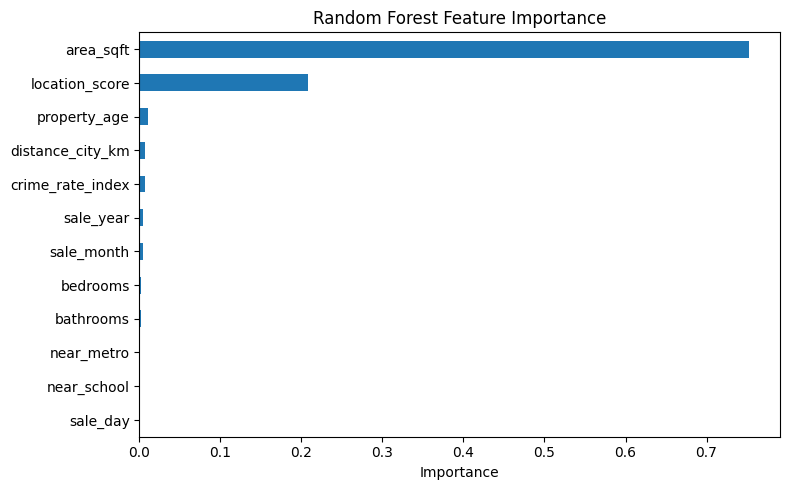

In [12]:
rf = fitted_tree_models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Part F: Support Vector Regression (SVR)

SVR is sensitive to feature scale, so each SVR is wrapped in a pipeline with `StandardScaler`. We compare linear, polynomial, and RBF kernels, then tune C, gamma, and epsilon for the RBF model using 3-fold cross-validation.

In [13]:
# Scale both input features and target prices for stable SVR optimization.
def make_scaled_svr(kernel, **kwargs):
    return TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), SVR(kernel=kernel, **kwargs)),
        transformer=StandardScaler()
    )

svr_models = {
    "Linear SVR": make_scaled_svr("linear", C=1.0, epsilon=0.1),
    "Polynomial SVR": make_scaled_svr("poly", degree=2, C=1.0, epsilon=0.1),
    "RBF SVR": make_scaled_svr("rbf", C=1.0, gamma="scale", epsilon=0.1)
}

svr_rows = []
for name, model in svr_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    svr_rows.append({"Model": name, **regression_metrics(y_test, pred)})
svr_comparison = pd.DataFrame(svr_rows)
display(svr_comparison.round(4))

,Model,MSE,MAE,RMSE,R2
0,Linear SVR,6.570671e+12,1.938395e+06,2.563332e+06,0.9184
1,Polynomial SVR,8.063672e+13,6.880244e+06,8.979795e+06,-0.0013
2,RBF SVR,6.224183e+12,1.815293e+06,2.494831e+06,0.9227


In [14]:
svr_rbf_pipeline = make_scaled_svr("rbf")
param_grid = {
    "regressor__svr__C": [1, 10, 100],
    "regressor__svr__gamma": ["scale", 0.01],
    "regressor__svr__epsilon": [0.1, 0.2]
}
svr_grid = GridSearchCV(
    svr_rbf_pipeline, param_grid, cv=3,
    scoring="neg_mean_squared_error", n_jobs=-1, verbose=0
)
svr_grid.fit(X_train, y_train)
best_svr = svr_grid.best_estimator_
best_svr_pred = best_svr.predict(X_test)

print("Best SVR parameters:", svr_grid.best_params_)
print("Best CV RMSE:", np.sqrt(-svr_grid.best_score_))
display(pd.DataFrame([{"Model": "Tuned RBF SVR", **regression_metrics(y_test, best_svr_pred)}]).round(4))

Best SVR parameters: {'regressor__svr__C': 10, 'regressor__svr__epsilon': 0.1, 'regressor__svr__gamma': 0.01}
Best CV RMSE: 2223763.0677785743


,Model,MSE,MAE,RMSE,R2
0,Tuned RBF SVR,5.027679e+12,1.637712e+06,2242248.586,0.9376


## Part G: Overall Model Comparison and Evaluation

This section evaluates all final models on the same held-out test set. MSE, MAE, RMSE, and R² are reported. A large train/test R² gap can indicate overfitting; low scores on both sets can indicate underfitting.

In [15]:
all_models = {
    "Ridge": ridge_model,
    "Lasso": lasso_model,
    **fitted_tree_models,
    **svr_models,
    "Tuned RBF SVR": best_svr
}

all_rows = []
for name, model in all_models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    all_rows.append({
        "Model": name,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "R2 gap (train-test)": r2_score(y_train, train_pred) - r2_score(y_test, test_pred)
    })

model_comparison = pd.DataFrame(all_rows).sort_values("Test RMSE")
display(model_comparison.round(4))

,Model,Train R2,Test R2,Train RMSE,Test RMSE,Test MAE,Test MSE,R2 gap (train-test)
8,Tuned RBF SVR,0.9399,0.9376,2.117488e+06,2.242249e+06,1.637712e+06,5.027679e+12,0.0023
4,Random Forest,0.9767,0.9290,1.319181e+06,2.390665e+06,1.745461e+06,5.715279e+12,0.0476
7,RBF SVR,0.9509,0.9227,1.913376e+06,2.494831e+06,1.815293e+06,6.224183e+12,0.0282
1,Lasso,0.9174,0.9199,2.482396e+06,2.539903e+06,1.945576e+06,6.451110e+12,-0.0025
0,Ridge,0.9174,0.9199,2.482399e+06,2.539952e+06,1.945385e+06,6.451358e+12,-0.0025
5,Linear SVR,0.9166,0.9184,2.495161e+06,2.563332e+06,1.938395e+06,6.570671e+12,-0.0019
3,Tuned Decision Tree,0.9621,0.8917,1.680808e+06,2.953891e+06,2.155391e+06,8.725474e+12,0.0705
2,Decision Tree,1.0000,0.8665,0.000000e+00,3.278407e+06,2.385454e+06,1.074795e+13,0.1335
6,Polynomial SVR,0.0173,-0.0013,8.562279e+06,8.979795e+06,6.880244e+06,8.063672e+13,0.0186


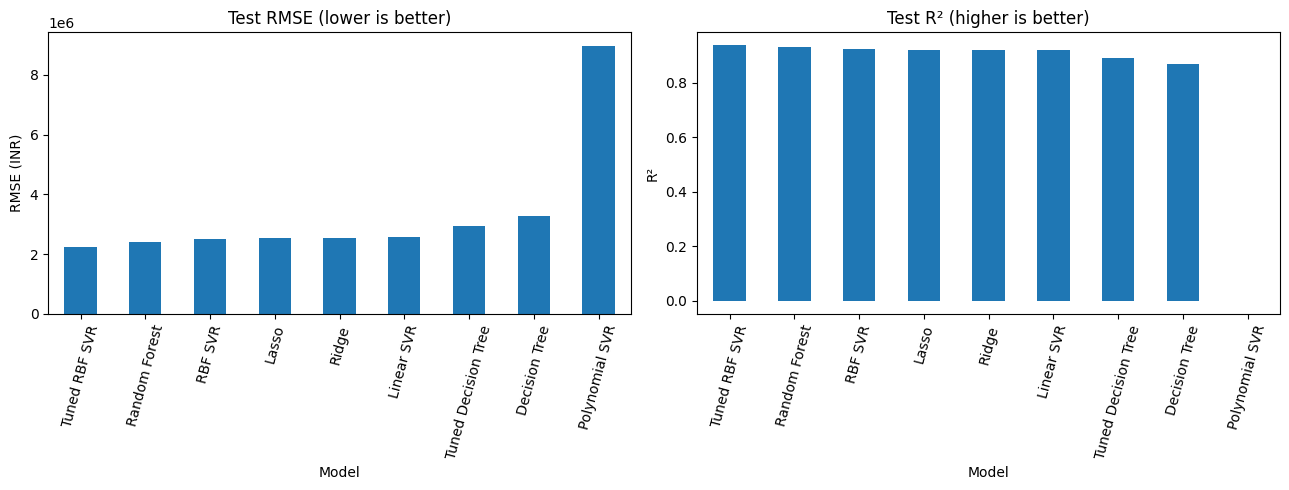

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
model_comparison.sort_values("Test RMSE").plot(
    x="Model", y="Test RMSE", kind="bar", ax=axes[0], legend=False, title="Test RMSE (lower is better)"
)
model_comparison.sort_values("Test R2", ascending=False).plot(
    x="Model", y="Test R2", kind="bar", ax=axes[1], legend=False, title="Test R² (higher is better)"
)
axes[0].set_ylabel("RMSE (INR)")
axes[1].set_ylabel("R²")
for ax in axes:
    ax.tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

## Part H: Final Analysis and Reporting

In [17]:
best_row = model_comparison.iloc[0]
best_name = best_row["Model"]
print("Best model by lowest test RMSE:", best_name)
print(f"Test RMSE: INR {best_row['Test RMSE']:,.2f}")
print(f"Test MAE:  INR {best_row['Test MAE']:,.2f}")
print(f"Test R2:   {best_row['Test R2']:.4f}")

print("\nInterpretation:")
print("- R² measures the fraction of target variance explained by the model; it is not classification accuracy.")
print("- MAE is the average absolute prediction error in INR.")
print("- RMSE penalizes larger errors more strongly than MAE.")
print("- Compare train and test scores to diagnose overfitting/underfitting.")
print("- Ridge shrinks coefficients; Lasso can zero out less useful coefficients.")
print("- Random Forest can capture nonlinear interactions, but may overfit if tree depth is uncontrolled.")
print("- SVR performance depends on scaling and hyperparameters.")
print("- If predicting future sales, prioritize time-aware validation and avoid using information unavailable at prediction time.")

Best model by lowest test RMSE: Tuned RBF SVR
Test RMSE: INR 2,242,248.59
Test MAE:  INR 1,637,712.15
Test R2:   0.9376

Interpretation:
- R² measures the fraction of target variance explained by the model; it is not classification accuracy.
- MAE is the average absolute prediction error in INR.
- RMSE penalizes larger errors more strongly than MAE.
- Compare train and test scores to diagnose overfitting/underfitting.
- Ridge shrinks coefficients; Lasso can zero out less useful coefficients.
- Random Forest can capture nonlinear interactions, but may overfit if tree depth is uncontrolled.
- SVR performance depends on scaling and hyperparameters.
- If predicting future sales, prioritize time-aware validation and avoid using information unavailable at prediction time.


In [18]:
# Save final comparison table for reporting
model_comparison.to_csv("regression_model_comparison.csv", index=False)
cv_comparison.to_csv("cross_validation_comparison.csv", index=False)
print("Saved: regression_model_comparison.csv and cross_validation_comparison.csv")

Saved: regression_model_comparison.csv and cross_validation_comparison.csv
